# 📊 매거진형 에디토리얼 저성과 Cutoff 분석

반복 전시되는 매거진형 에디토리얼의 **Full Engagement 분포를 확인하고 저성과 Cutoff 후보를 검토**하는 분석입니다.

- 분석 기간: 2026년 W01~W20
- 분석 단위: 주차 × 에디토리얼
- 핵심 지표: 일평균 Full Engagement
- 분석 흐름: 전시일수 보정 → Percentile → Histogram → CDF → KDE

> 공개용 Notebook에서는 실제 회사 데이터 대신 합성 `sample_engagement.csv`를 사용합니다.


In [1]:
### 라이브러리 호출
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from datetime import datetime, timedelta
from pathlib import Path

print("라이브러리 호출 완료")


라이브러리 호출 완료


## 1. 주차 기준 생성

원본 분석과 동일하게 2026-01-01을 W01 시작일로 두고 7일 단위 주차 테이블을 생성합니다.


In [2]:
### 주차 기준 생성
start_date = datetime(2026, 1, 1)
end_date = datetime(2026, 12, 30)

weeks = []
current_date = start_date

for week_num in range(1, 53):
    week_label = f'26Y W{str(week_num).zfill(2)}'
    end_of_week = current_date + timedelta(days=6)
    weeks.append({
        'Week': week_label,
        'Week Start Date': current_date.strftime('%Y-%m-%d'),
        'Week End Date': end_of_week.strftime('%Y-%m-%d')
    })
    current_date = end_of_week + timedelta(days=1)

df_weeks = pd.DataFrame(weeks)

df_weeks['Week Start Date'] = pd.to_datetime(df_weeks['Week Start Date']).dt.normalize()
df_weeks['Week End Date'] = pd.to_datetime(df_weeks['Week End Date']).dt.normalize()

print(f"주차 수: {len(df_weeks)}")
display(df_weeks.head(3))


주차 수: 52


,Week,Week Start Date,Week End Date
0,26Y W01,2026-01-01,2026-01-07
1,26Y W02,2026-01-08,2026-01-14
2,26Y W03,2026-01-15,2026-01-21


## 2. 공개용 Sample Data 호출

실제 분석에서는 주차별 에디토리얼 메타데이터와 Engagement 집계 파일을 병합했습니다.  
공개용 Notebook에서는 동일 분석 컬럼을 포함한 합성 데이터를 한 파일로 구성했습니다.


In [3]:
### 데이터 호출
data_path = Path("../sample_data/sample_engagement.csv")

if not data_path.exists():
    data_path = Path("/mnt/data/sample_engagement.csv")

df = pd.read_csv(data_path)

print(f"데이터 크기: {df.shape[0]:,}행 × {df.shape[1]}열")
display(df.head(3))


데이터 크기: 401행 × 9열


,Week,Component Key,Component Title,Display Type,Category,Price Type,Life Start Date,Life End Date,Full Engagement
0,26Y W01,editorial_001,Editorial 001,Basic Card,Game,Free,2026-01-01,2026-02-15,1750
1,26Y W02,editorial_001,Editorial 001,Basic Card,Game,Free,2026-01-01,2026-02-15,1848
2,26Y W03,editorial_001,Editorial 001,Basic Card,Game,Free,2026-01-01,2026-02-15,1939


In [4]:
### 날짜형 변환
df['Life Start Date'] = pd.to_datetime(df['Life Start Date']).dt.normalize()
df['Life End Date'] = pd.to_datetime(df['Life End Date']).dt.normalize()

print("날짜형 변환 완료")
display(df[['Week', 'Component Key', 'Life Start Date', 'Life End Date']].head(3))


날짜형 변환 완료


,Week,Component Key,Life Start Date,Life End Date
0,26Y W01,editorial_001,2026-01-01,2026-02-15
1,26Y W02,editorial_001,2026-01-01,2026-02-15
2,26Y W03,editorial_001,2026-01-01,2026-02-15


## 3. 실제 전시일수 및 일평균 Full Engagement 계산

에디토리얼별 전체 운영 기간과 각 주차 범위를 비교해 실제 전시일수를 계산합니다.  
이후 주차별 Full Engagement를 실제 전시일수로 나누어 일평균 성과를 산출합니다.


In [5]:
### 주차 정보 결합
df = df.merge(df_weeks, on='Week', how='left')

print(f"주차 정보 결합 후 데이터 크기: {df.shape}")
display(df[['Week', 'Component Key', 'Week Start Date', 'Week End Date']].head(3))


주차 정보 결합 후 데이터 크기: (401, 11)


,Week,Component Key,Week Start Date,Week End Date
0,26Y W01,editorial_001,2026-01-01,2026-01-07
1,26Y W02,editorial_001,2026-01-08,2026-01-14
2,26Y W03,editorial_001,2026-01-15,2026-01-21


In [6]:
### 실제 전시일수 계산
df['Actual Start Date'] = df[['Life Start Date', 'Week Start Date']].max(axis=1)
df['Actual End Date'] = df[['Life End Date', 'Week End Date']].min(axis=1)

df = df[[
    'Week',
    'Component Key',
    'Component Title',
    'Display Type',
    'Category',
    'Price Type',
    'Actual Start Date',
    'Actual End Date',
    'Full Engagement'
]]

df['Display Days'] = (
    df['Actual End Date'] - df['Actual Start Date']
).dt.days + 1

df['Full Engagement(Avg.)'] = (
    df['Full Engagement'] / df['Display Days']
)

print(
    f"Display Days 범위: {df['Display Days'].min()}~"
    f"{df['Display Days'].max()}일"
)
display(df.head(5))


Display Days 범위: 4~7일


,Week,Component Key,Component Title,Display Type,Category,Price Type,Actual Start Date,Actual End Date,Full Engagement,Display Days,Full Engagement(Avg.)
0,26Y W01,editorial_001,Editorial 001,Basic Card,Game,Free,2026-01-01,2026-01-07,1750,7,250.0
1,26Y W02,editorial_001,Editorial 001,Basic Card,Game,Free,2026-01-08,2026-01-14,1848,7,264.0
2,26Y W03,editorial_001,Editorial 001,Basic Card,Game,Free,2026-01-15,2026-01-21,1939,7,277.0
3,26Y W04,editorial_001,Editorial 001,Basic Card,Game,Free,2026-01-22,2026-01-28,2037,7,291.0
4,26Y W05,editorial_001,Editorial 001,Basic Card,Game,Free,2026-01-29,2026-02-04,2128,7,304.0


## 4. Percentile Analysis

전체 에디토리얼의 일평균 Full Engagement를 기준으로 주요 Percentile을 확인합니다.


In [7]:
### Percentile 계산
fe = df['Full Engagement(Avg.)']

percentiles = {
    'P10': np.percentile(fe, 10),
    'P25': np.percentile(fe, 25),
    'Median(P50)': np.percentile(fe, 50),
    'P75': np.percentile(fe, 75),
    'P90': np.percentile(fe, 90)
}

percentile_df = pd.DataFrame({
    'Percentile': percentiles.keys(),
    'Full Engagement': percentiles.values()
})

percentile_df['Full Engagement'] = percentile_df['Full Engagement'].round(0).astype(int)

print("주요 Percentile")
display(percentile_df)


주요 Percentile


,Percentile,Full Engagement
0,P10,792
1,P25,1965
2,Median(P50),3117
3,P75,5168
4,P90,9271


## 5. Histogram

전체 일평균 Full Engagement 분포를 확인합니다.  
일부 고성과 에디토리얼이 높은 값을 기록하는 Long-tail 형태인지 확인하는 단계입니다.


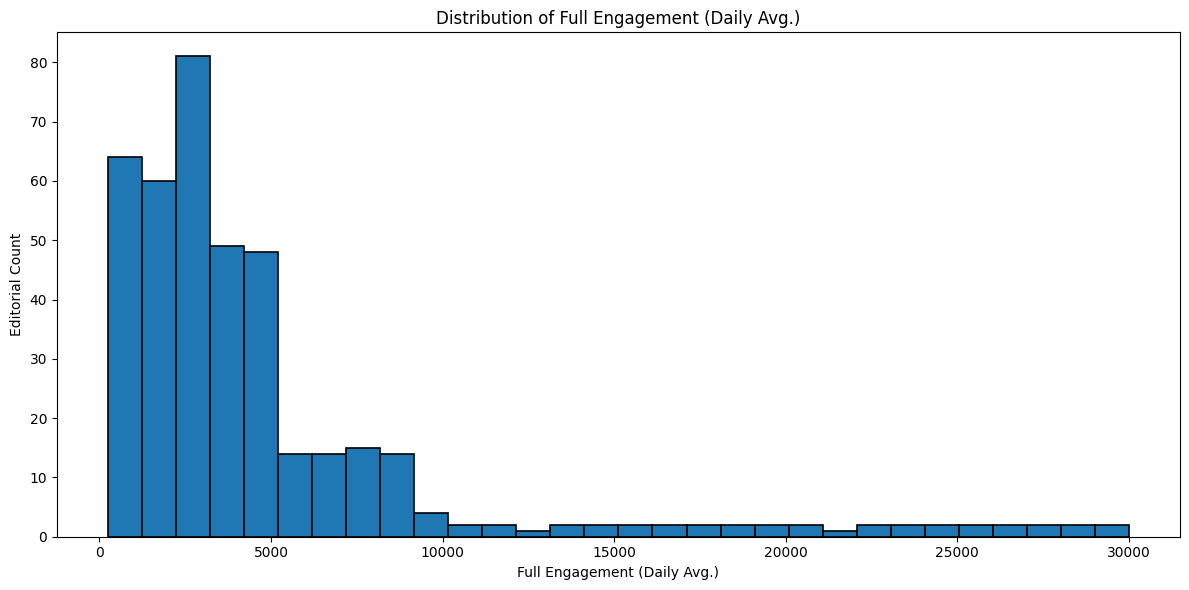

최소값: 250 / 중앙값: 3,117 / 최대값: 30,000


In [8]:
### Histogram
plt.figure(figsize=(12, 6))

plt.hist(
    fe,
    bins=30,
    edgecolor='black',
    linewidth=1.2
)

plt.xlabel('Full Engagement (Daily Avg.)')
plt.ylabel('Editorial Count')
plt.title('Distribution of Full Engagement (Daily Avg.)')
plt.tight_layout()
plt.show()

print(
    f"최소값: {fe.min():,.0f} / "
    f"중앙값: {fe.median():,.0f} / "
    f"최대값: {fe.max():,.0f}"
)


## 6. CDF Plot

특정 Full Engagement 값 이하의 에디토리얼이 전체에서 어느 정도 비중을 차지하는지 확인합니다.  
원본 분석과 동일하게 P10, P25, P50, P75, P90 위치를 함께 표시합니다.


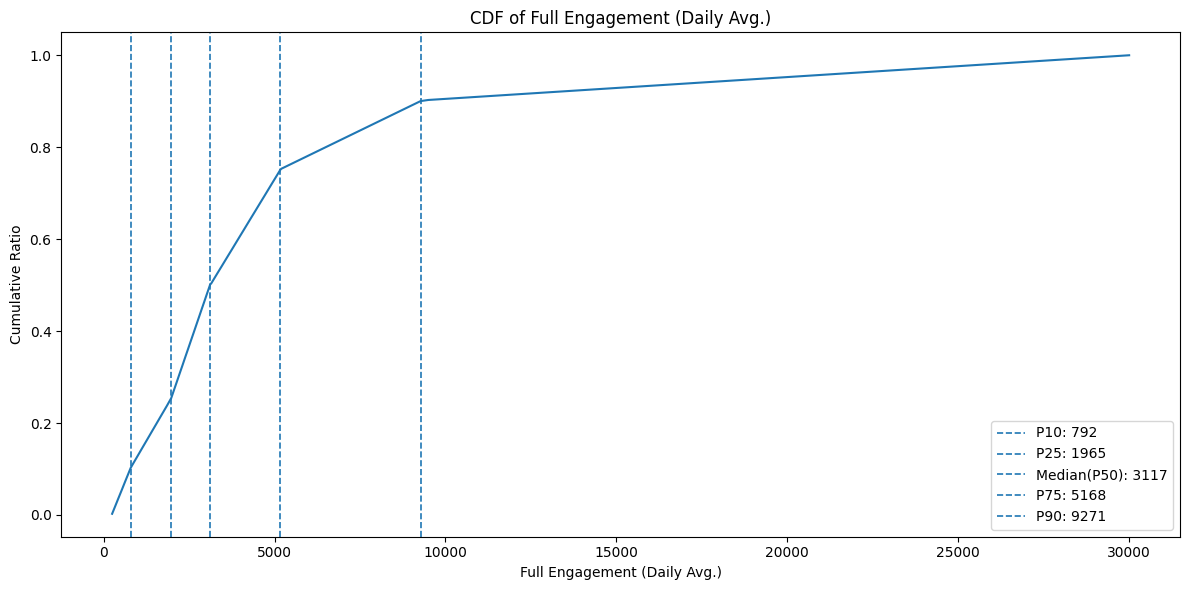

P25 Cutoff 후보: 1,965


In [9]:
### CDF Plot
x = np.sort(fe)
y = np.arange(1, len(x) + 1) / len(x)

plt.figure(figsize=(12, 6))
plt.plot(x, y, linewidth=1.5)

for label, value in percentiles.items():
    plt.axvline(
        value,
        linestyle='--',
        linewidth=1.2,
        label=f'{label}: {value:.0f}'
    )

plt.xlabel('Full Engagement (Daily Avg.)')
plt.ylabel('Cumulative Ratio')
plt.title('CDF of Full Engagement (Daily Avg.)')
plt.legend()
plt.tight_layout()
plt.show()

print(f"P25 Cutoff 후보: {percentiles['P25']:,.0f}")


## 7. KDE Plot

에디토리얼 성과가 집중되는 구간과 주요 Percentile의 위치를 확인합니다.  
원본 분석과 동일하게 저성과 구간을 보기 쉽도록 x축 상한을 5,000으로 제한합니다.


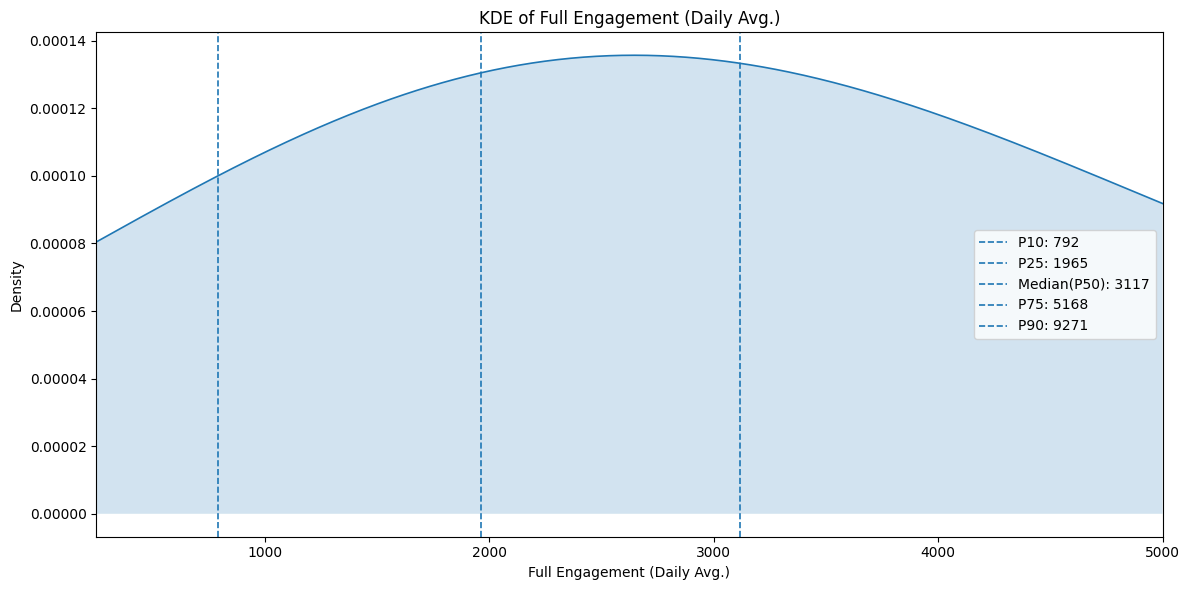

저성과 Cutoff 검토 기준: P25 = 1,965


In [10]:
### KDE Plot
kde = gaussian_kde(fe)
x_kde = np.linspace(fe.min(), 5000, 500)
y_kde = kde(x_kde)

plt.figure(figsize=(12, 6))
plt.plot(x_kde, y_kde, linewidth=1.2)
plt.fill_between(x_kde, y_kde, alpha=0.2)

for label, value in percentiles.items():
    plt.axvline(
        value,
        linestyle='--',
        linewidth=1.2,
        label=f'{label}: {value:.0f}'
    )

plt.xlim(fe.min(), 5000)
plt.xlabel('Full Engagement (Daily Avg.)')
plt.ylabel('Density')
plt.title('KDE of Full Engagement (Daily Avg.)')
plt.legend()
plt.tight_layout()
plt.show()

print(
    "저성과 Cutoff 검토 기준: "
    f"P25 = {percentiles['P25']:,.0f}"
)


## 8. 분석 결과

- P10: **792**
- P25: **1,965**
- Median(P50): **3,117**
- P75: **5,168**
- P90: **9,271**
- 전체 분포에서 P25 이하 구간을 저성과 Cutoff 후보로 검토
- 사전에 제안했던 Full Engagement 2,000 이하 기준과 P25가 근접한 수준인지 확인

> 3-Out은 운영 정책 제안에 해당하며, 본 Notebook의 원본 Python 분석 범위는 분포 및 Percentile 기반 Cutoff 검토까지입니다.
